# Task 5 - Web Data Extraction & Analysis
Google My Business listings of restaurants in Singapore (`google-my-business-sg.csv`, pipe-separated).

## 1. Load the data

In [1]:
import ast
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 45)

raw = pd.read_csv("google-my-business-sg.csv", sep="|")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (200, 11)


,location_id,location_name,address,phone_numbers,latitude,longitude,price,regular_hours,service_options,average_rating,labels
0,ChIJPZfhC3sZ2jERSbIJON8tn4A,Al Majlis Serangoon Road,"452 Serangoon Rd, Singapore 218140",+65 8180 2525,1.313198,103.856764,SGD 10–20,"{'tuesday': '11\u202fAM–3\u202fAM', 'wedn...","{'dine_in': True, 'takeout': True, 'deliv...",4.6,Halal restaurant
1,ChIJZ_cTnrsZ2jER88FNG6_95w0,Al-Jilani Restaurant,"127 Bencoolen St, Singapore 189637",NaN,1.300819,103.851748,SGD 1–10,"{'tuesday': 'Open 24 hours', 'wednesday':...","{'dine_in': True, 'takeout': True, 'deliv...",4.1,Halal restaurant
2,ChIJ-acM4LcZ2jERI5kCVYDvokk,Qtech Cafe Restaurant,"211 Syed Alwi Rd, Singapore 207744",+65 9639 6395,1.307781,103.857714,SGD 10–20,"{'tuesday': '11\u202fAM–4\u202fPM, 6\u202...","{'dine_in': True, 'takeout': True, 'deliv...",4.4,Restaurant
3,ChIJlW0um74R2jERJB9IfmT4Qmo,Rasa Rasa @ Teck Whye,"160A Jln Teck Whye, Singapore 681160",+65 6763 2685,1.380381,103.757299,SGD 10–20,"{'tuesday': '6\u202fAM–1\u202fAM', 'wedne...","{'dine_in': True, 'takeout': True, 'deliv...",4.0,Halal restaurant
4,ChIJtcvgd4oQ2jERYftwlvgqa68,Time For Thai Halal Restaurant @ Bukit Timah,"15 Cheong Chin Nam Rd, Singapore 599739",+65 6909 3903,1.343169,103.775155,SGD 10–20,"{'tuesday': '11\u202fAM–1\u202fAM', 'wedn...","{'dine_in': True, 'takeout': True, 'no_co...",3.8,Thai restaurant


## 2. Inspect data quality

In [2]:
print("Missing values:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nFully duplicated rows:", raw.duplicated().sum())
print("Unique locations     :", raw["location_id"].nunique())
print("\nPrice values:")
print(raw.drop_duplicates()["price"].value_counts(dropna=False))

Missing values:
phone_numbers    50
price            10
dtype: int64

Fully duplicated rows: 180
Unique locations     : 20

Price values:
price
SGD 10–20    9
SGD 1–10     5
SGD 20–30    3
$$           1
NaN          1
SGD 20–40    1
Name: count, dtype: int64


## 3. Clean and structure the data

In [3]:
def to_minutes(text, default_meridiem=None):
    m = re.match(r"(\d{1,2})(?::(\d{2}))?\s*(AM|PM)?", text.strip())
    hour, minute = int(m.group(1)), int(m.group(2) or 0)
    meridiem = m.group(3) or default_meridiem
    hour = hour % 12 + (12 if meridiem == "PM" else 0)
    return hour * 60 + minute


def range_hours(rng):
    start, end = [s.strip() for s in rng.split("–")]
    end_meridiem = re.search(r"(AM|PM)", end).group(1)
    return ((to_minutes(end) - to_minutes(start, end_meridiem)) % 1440) / 60


def day_hours(text):
    if text == "Closed":
        return 0.0
    if text == "Open 24 hours":
        return 24.0
    return sum(range_hours(r) for r in text.split(","))


DAYS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]


def clean_listings(raw):
    df = raw.drop_duplicates().reset_index(drop=True)
    df["location_name"] = df["location_name"].str.strip()
    df["phone_numbers"] = df["phone_numbers"].fillna("Not available")
    df["postal_code"] = df["address"].str.extract(r"Singapore (\d{6})")[0]
    df["postal_district"] = df["postal_code"].str[:2]
    cuisine = df["labels"].str.replace(r"\s*(restaurant|stall)$", "", case=False, regex=True)
    df["cuisine"] = cuisine.replace("", "General")

    price = df["price"].str.extract(r"SGD\s*(\d+)\D+(\d+)").astype(float)
    df["price_label"] = df["price"].replace({"$$": "Mid-range"}).fillna("Unknown")
    df["price_min"], df["price_max"] = price[0], price[1]
    df["price_mid"] = (df["price_min"] + df["price_max"]) / 2

    hours = df["regular_hours"].apply(ast.literal_eval)
    hours_df = pd.DataFrame({d: hours.apply(lambda h: day_hours(h[d])) for d in DAYS})
    df["weekly_open_hours"] = hours_df.sum(axis=1)
    df["avg_daily_open_hours"] = hours_df.mean(axis=1).round(1)
    df["closed_days"] = (hours_df == 0).sum(axis=1)
    df["open_24h"] = hours.apply(lambda h: all(v == "Open 24 hours" for v in h.values()))

    services = pd.DataFrame(list(df["service_options"].apply(ast.literal_eval)))
    services = services.fillna(False).astype(bool).add_prefix("svc_")
    df = pd.concat([df, services], axis=1)
    df["num_services"] = services.sum(axis=1)

    df["rating_band"] = pd.cut(df["average_rating"], bins=[0, 3.9, 4.4, 5],
                               labels=["Average (<4.0)", "Good (4.0-4.4)", "Excellent (4.5+)"])
    keep = ["location_id", "location_name", "address", "postal_code", "postal_district",
            "phone_numbers", "latitude", "longitude", "cuisine", "labels", "price_label",
            "price_min", "price_max", "price_mid", "average_rating", "rating_band",
            "weekly_open_hours", "avg_daily_open_hours", "closed_days", "open_24h",
            "num_services"] + list(services.columns)
    return df[keep], hours_df.set_index(df["location_name"])


clean, weekly_hours = clean_listings(raw)
print("Clean shape:", clean.shape)
clean.head()

Clean shape: (20, 27)


,location_id,location_name,address,postal_code,postal_district,phone_numbers,latitude,longitude,cuisine,labels,price_label,price_min,price_max,price_mid,average_rating,rating_band,weekly_open_hours,avg_daily_open_hours,closed_days,open_24h,num_services,svc_dine_in,svc_takeout,svc_delivery,svc_no_contact_delivery,svc_drive_through,svc_curbside_pickup
0,ChIJPZfhC3sZ2jERSbIJON8tn4A,Al Majlis Serangoon Road,"452 Serangoon Rd, Singapore 218140",218140,21,+65 8180 2525,1.313198,103.856764,Halal,Halal restaurant,SGD 10–20,10.0,20.0,15.0,4.6,Excellent (4.5+),112.0,16.0,0,False,3,True,True,True,False,False,False
1,ChIJZ_cTnrsZ2jER88FNG6_95w0,Al-Jilani Restaurant,"127 Bencoolen St, Singapore 189637",189637,18,Not available,1.300819,103.851748,Halal,Halal restaurant,SGD 1–10,1.0,10.0,5.5,4.1,Good (4.0-4.4),168.0,24.0,0,True,3,True,True,True,False,False,False
2,ChIJ-acM4LcZ2jERI5kCVYDvokk,Qtech Cafe Restaurant,"211 Syed Alwi Rd, Singapore 207744",207744,20,+65 9639 6395,1.307781,103.857714,General,Restaurant,SGD 10–20,10.0,20.0,15.0,4.4,Good (4.0-4.4),83.0,11.9,0,False,3,True,True,True,False,False,False
3,ChIJlW0um74R2jERJB9IfmT4Qmo,Rasa Rasa @ Teck Whye,"160A Jln Teck Whye, Singapore 681160",681160,68,+65 6763 2685,1.380381,103.757299,Halal,Halal restaurant,SGD 10–20,10.0,20.0,15.0,4.0,Good (4.0-4.4),133.0,19.0,0,False,3,True,True,True,False,False,False
4,ChIJtcvgd4oQ2jERYftwlvgqa68,Time For Thai Halal Restaurant @ Bukit Timah,"15 Cheong Chin Nam Rd, Singapore 599739",599739,59,+65 6909 3903,1.343169,103.775155,Thai,Thai restaurant,SGD 10–20,10.0,20.0,15.0,3.8,Average (<4.0),98.0,14.0,0,False,3,True,True,False,True,False,False


In [4]:
clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 27 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   location_id              20 non-null     str     
 1   location_name            20 non-null     str     
 2   address                  20 non-null     str     
 3   postal_code              20 non-null     str     
 4   postal_district          20 non-null     str     
 5   phone_numbers            20 non-null     str     
 6   latitude                 20 non-null     float64 
 7   longitude                20 non-null     float64 
 8   cuisine                  20 non-null     str     
 9   labels                   20 non-null     str     
 10  price_label              20 non-null     str     
 11  price_min                18 non-null     float64 
 12  price_max                18 non-null     float64 
 13  price_mid                18 non-null     float64 
 14  average_rating         

## 4. Export to CSV and Excel

In [5]:
cuisine_summary = (clean.groupby("cuisine")
                   .agg(restaurants=("location_id", "count"),
                        avg_rating=("average_rating", "mean"),
                        avg_price_mid=("price_mid", "mean"),
                        avg_weekly_open_hours=("weekly_open_hours", "mean"))
                   .round(2).sort_values("avg_rating", ascending=False))

clean.to_csv("gmb_cleaned.csv", index=False)
with pd.ExcelWriter("gmb_cleaned.xlsx") as writer:
    clean.to_excel(writer, sheet_name="Cleaned_Data", index=False)
    cuisine_summary.to_excel(writer, sheet_name="Cuisine_Summary")
    weekly_hours.to_excel(writer, sheet_name="Daily_Open_Hours")

print("Saved: gmb_cleaned.csv, gmb_cleaned.xlsx")
cuisine_summary

Saved: gmb_cleaned.csv, gmb_cleaned.xlsx


,restaurants,avg_rating,avg_price_mid,avg_weekly_open_hours
cuisine,,,,
Brunch,1,4.60,25.00,80.50
Burmese,1,4.50,5.50,70.00
Turkish,1,4.40,15.00,58.00
General,1,4.40,15.00,83.00
Halal,10,4.37,16.78,102.70
Indian,1,4.20,NaN,84.00
Western,2,3.90,10.25,123.38
Thai,1,3.80,15.00,98.00
Asian,1,3.70,5.50,168.00


## 5. Exploratory analysis

In [6]:
clean[["average_rating", "price_mid", "weekly_open_hours", "num_services"]].describe().round(2)

,average_rating,price_mid,weekly_open_hours,num_services
count,20.00,18.00,20.00,20.00
mean,4.24,14.86,100.31,2.90
std,0.40,7.58,33.89,0.31
min,3.40,5.50,58.00,2.00
25%,3.98,7.88,80.06,3.00
50%,4.30,15.00,84.00,3.00
75%,4.53,15.00,113.75,3.00
max,4.90,30.00,168.00,3.00


In [7]:
clean.sort_values("average_rating", ascending=False).head(5)[
    ["location_name", "cuisine", "price_label", "average_rating", "weekly_open_hours"]]

,location_name,cuisine,price_label,average_rating,weekly_open_hours
18,INDIAN SAAGA - HALAL NORTH INDIAN RESTAURANT,Halal,SGD 20–30,4.9,84.0
17,RIB Soul Food - By The Halal Mixologist,Halal,SGD 20–40,4.7,71.5
0,Al Majlis Serangoon Road,Halal,SGD 10–20,4.6,112.0
16,The Malayan Council,Halal,Unknown,4.6,84.0
14,Brunch Club by The Halal Corner,Brunch,SGD 20–30,4.6,80.5


In [8]:
price_summary = (clean.groupby("price_label")
                 .agg(restaurants=("location_id", "count"), avg_rating=("average_rating", "mean"))
                 .round(2).sort_values("avg_rating", ascending=False))
price_summary

,restaurants,avg_rating
price_label,,
SGD 20–40,1,4.70
Unknown,1,4.60
SGD 20–30,3,4.57
SGD 10–20,9,4.21
Mid-range,1,4.20
SGD 1–10,5,3.92


In [9]:
service_cols = [c for c in clean.columns if c.startswith("svc_")]
clean[service_cols].sum().sort_values(ascending=False).rename("restaurants_offering")

svc_dine_in                20
svc_takeout                17
svc_delivery               10
svc_no_contact_delivery     8
svc_drive_through           2
svc_curbside_pickup         1
Name: restaurants_offering, dtype: int64

## 6. Visualizations

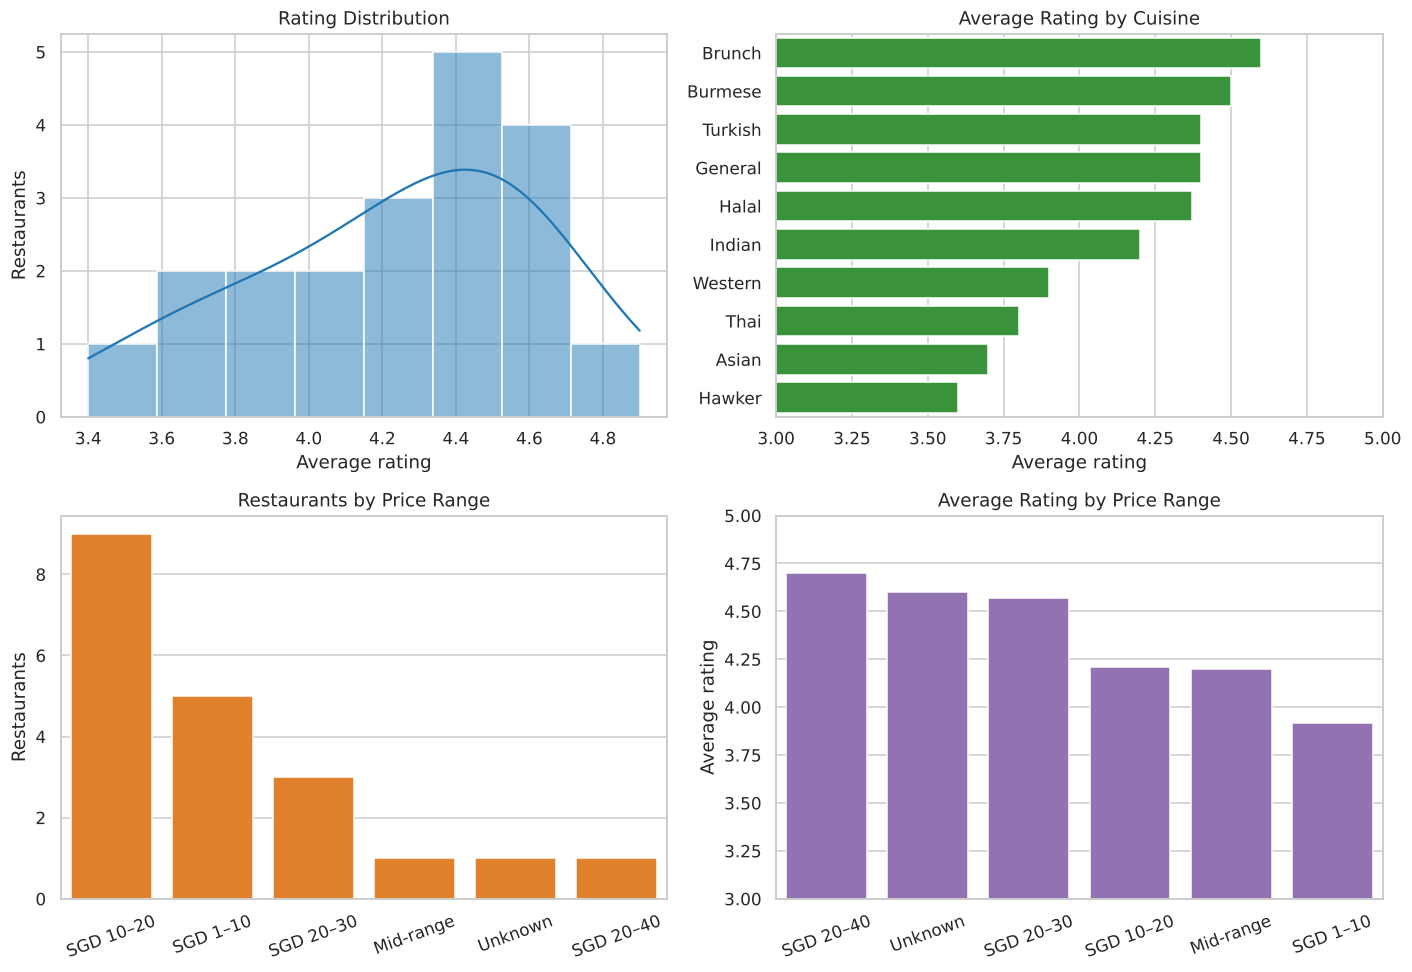

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(clean["average_rating"], bins=8, kde=True, ax=ax[0, 0], color="tab:blue")
ax[0, 0].set(title="Rating Distribution", xlabel="Average rating", ylabel="Restaurants")

cs = cuisine_summary.reset_index()
sns.barplot(data=cs, y="cuisine", x="avg_rating", ax=ax[0, 1], color="tab:green")
ax[0, 1].set(title="Average Rating by Cuisine", xlabel="Average rating", ylabel="", xlim=(3, 5))

sns.countplot(data=clean, x="price_label", ax=ax[1, 0], color="tab:orange",
              order=clean["price_label"].value_counts().index)
ax[1, 0].set(title="Restaurants by Price Range", xlabel="", ylabel="Restaurants")
ax[1, 0].tick_params(axis="x", rotation=20)

ps = price_summary.reset_index()
sns.barplot(data=ps, x="price_label", y="avg_rating", ax=ax[1, 1], color="tab:purple")
ax[1, 1].set(title="Average Rating by Price Range", xlabel="", ylabel="Average rating", ylim=(3, 5))
ax[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

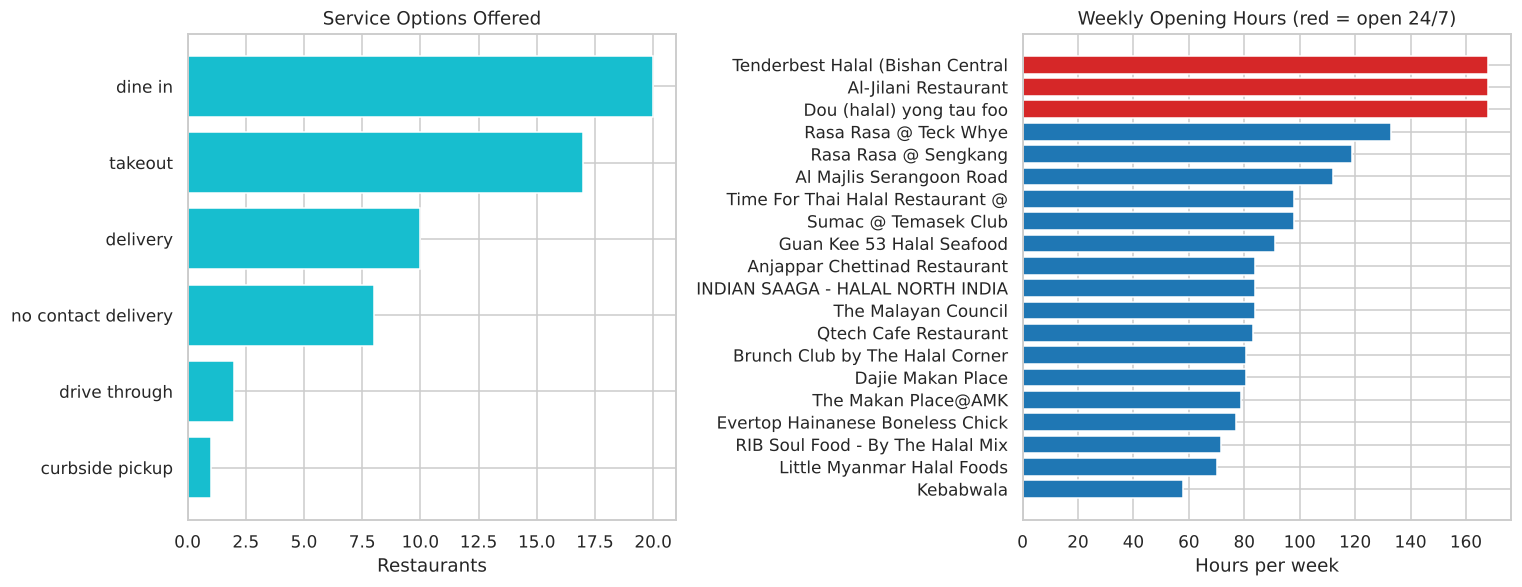

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
svc = clean[service_cols].sum().sort_values()
svc.index = svc.index.str.replace("svc_", "", regex=False).str.replace("_", " ")
ax[0].barh(svc.index, svc.values, color="tab:cyan")
ax[0].set(title="Service Options Offered", xlabel="Restaurants")

wh = clean.sort_values("weekly_open_hours").set_index("location_name")["weekly_open_hours"]
colors = ["tab:red" if v >= 168 else "tab:blue" for v in wh.values]
ax[1].barh(wh.index.str.slice(0, 32), wh.values, color=colors)
ax[1].set(title="Weekly Opening Hours (red = open 24/7)", xlabel="Hours per week")
plt.tight_layout()
plt.show()

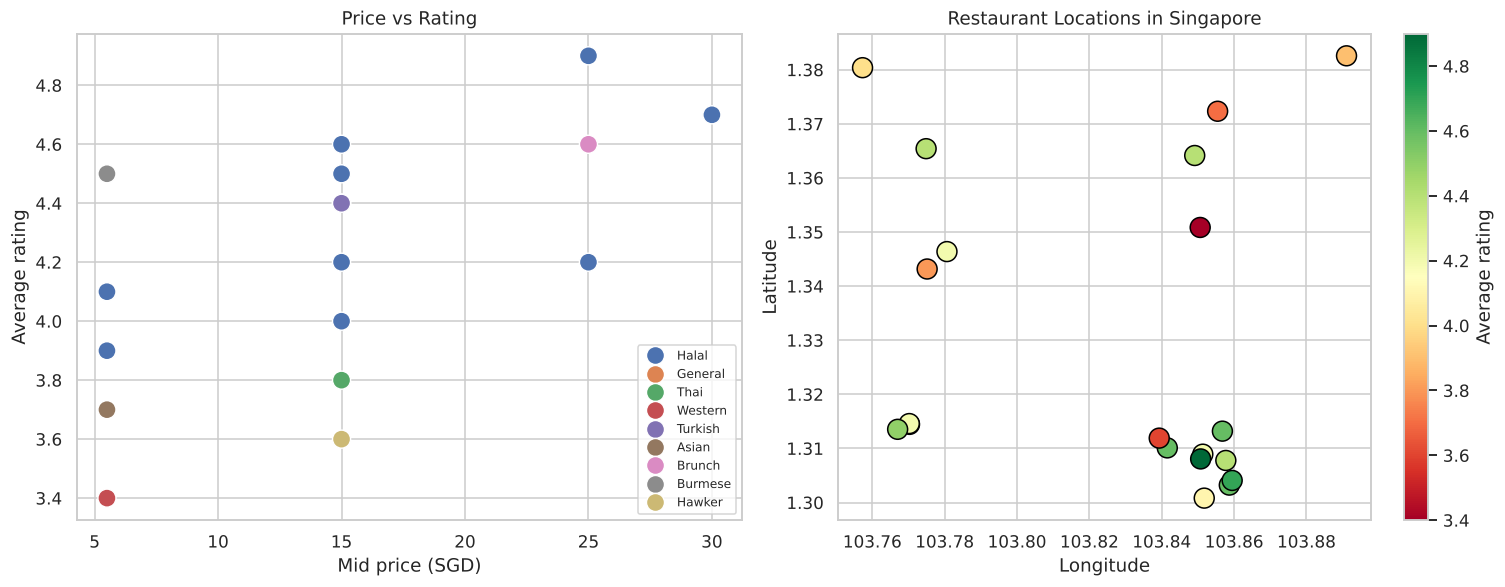

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=clean.dropna(subset=["price_mid"]), x="price_mid", y="average_rating",
                hue="cuisine", s=140, ax=ax[0])
ax[0].set(title="Price vs Rating", xlabel="Mid price (SGD)", ylabel="Average rating")
ax[0].legend(fontsize=8, loc="lower right")

sc = ax[1].scatter(clean["longitude"], clean["latitude"], c=clean["average_rating"],
                   cmap="RdYlGn", s=170, edgecolor="black")
plt.colorbar(sc, ax=ax[1], label="Average rating")
ax[1].set(title="Restaurant Locations in Singapore", xlabel="Longitude", ylabel="Latitude")
plt.tight_layout()
plt.show()

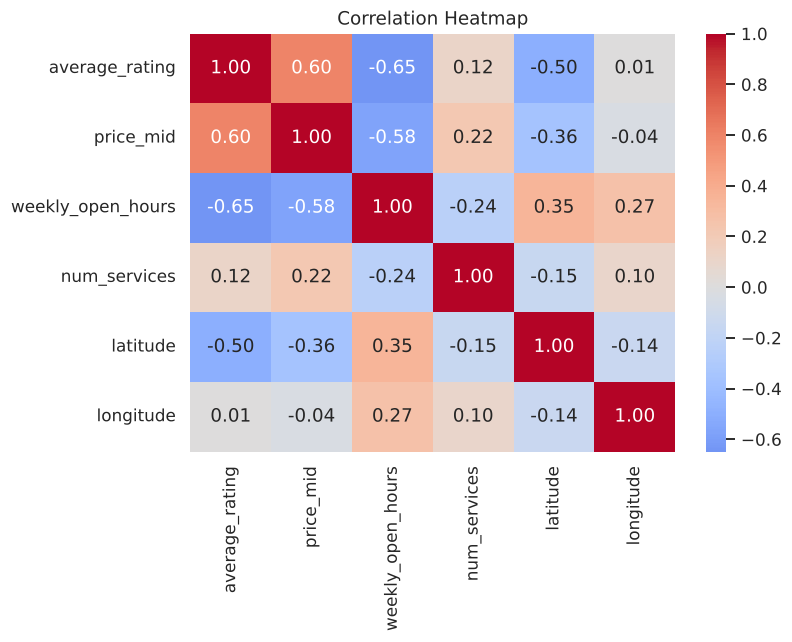

In [13]:
num = clean[["average_rating", "price_mid", "weekly_open_hours", "num_services",
             "latitude", "longitude"]]
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 7. Key findings

In [14]:
best = clean.loc[clean["average_rating"].idxmax()]
top_cuisine = cuisine_summary.index[0]
corr = clean[["price_mid", "average_rating"]].corr().iloc[0, 1]
print(f"Unique restaurants analysed : {len(clean)}")
print(f"Average rating              : {clean['average_rating'].mean():.2f}")
print(f"Highest rated               : {best['location_name']} ({best['average_rating']})")
print(f"Top cuisine by avg rating   : {top_cuisine} ({cuisine_summary.iloc[0]['avg_rating']:.2f})")
print(f"Most common price range     : {clean['price_label'].mode()[0]}")
print(f"Price vs rating correlation : {corr:.2f}")
print(f"Open 24 hours, 7 days       : {int(clean['open_24h'].sum())} restaurant(s)")
print(f"Offering delivery           : {int(clean.filter(like='delivery').any(axis=1).sum())} restaurants")
print(f"Missing phone numbers       : {(clean['phone_numbers'] == 'Not available').sum()}")

Unique restaurants analysed : 20
Average rating              : 4.24
Highest rated               : INDIAN SAAGA - HALAL NORTH INDIAN RESTAURANT (4.9)
Top cuisine by avg rating   : Brunch (4.60)
Most common price range     : SGD 10–20
Price vs rating correlation : 0.60
Open 24 hours, 7 days       : 3 restaurant(s)
Offering delivery           : 18 restaurants
Missing phone numbers       : 5
